In [ ]:
%pip install -q mediapipe opencv-python pandas matplotlib imageio-ffmpeg

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json
from pathlib import Path

DATA_FOLDER     = "data/raw/ASL"
MAX_SIGNS       = 10
VIDEOS_PER_SIGN = 5

RUN_NAME             = "asl_test" 
REPETITIONS          = 1
RANDOM_SEEDS         = [0, 1, 2]
SAVE_DEGRADED_VIDEOS = True
CACHE_FOLDER         = "cache"

PREPROCESS = [{"type": "resolution", "height": 720},
              {"type": "fps", "fps": 30}]

RUN_TESTS = ["resolution", "fps", "compression", "codec"]

TESTS_FILE = "tests.txt"     # test definitions (JSON), shared with sapiens_pipeline.ipynb
TESTS      = json.loads(Path(TESTS_FILE).read_text(encoding="utf-8"))

MEDIAPIPE_SETTINGS = {
    "model_complexity":         [1],
    "min_detection_confidence": [0.5],
}

KEYPOINT_GROUPS = ["body", "left_hand", "right_hand"]
PCK_ALPHA       = 0.1                           

LIMITS = {        
    "confidence":        ">= 0.75",
    "pck":               ">= 0.90",
    "detected_any_hand": ">= 0.75",
}

In [ ]:
import hashlib, itertools, json, shutil, subprocess, tempfile, time, urllib.request, warnings, zlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

warnings.simplefilter("ignore", RuntimeWarning)
pd.set_option("display.max_columns", 40)
VIDEO_TYPES = {".mp4", ".mov", ".avi", ".mkv", ".webm"}

In [ ]:
def ffmpeg():
    """ffmpeg from PATH, otherwise the copy that comes with the imageio-ffmpeg package."""
    exe = shutil.which("ffmpeg")
    if exe:
        return exe
    import imageio_ffmpeg
    return imageio_ffmpeg.get_ffmpeg_exe()


def read_video(path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    frames = []
    ok, frame = cap.read()
    while ok:
        frames.append(frame)
        ok, frame = cap.read()
    cap.release()
    if not frames:
        raise IOError(f"Could not read any frames from {path}")
    info = Path(str(path) + ".json")
    if info.exists():
        fps = json.loads(info.read_text())["fps"]
    return frames, float(fps)


def even(frames):
    """Most codecs need an even width and height."""
    h, w = frames[0].shape[:2]
    return [f[: h - h % 2, : w - w % 2] for f in frames]


def encode(frames, fps, path, codec, options):
    h, w = frames[0].shape[:2]
    cmd = [ffmpeg(), "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{w}x{h}",
           "-r", str(fps), "-i", "-", "-an", "-c:v", codec, *map(str, options), str(path)]
    subprocess.run(cmd, input=b"".join(f.tobytes() for f in frames), capture_output=True, check=True)


def save_video(frames, fps, path, codec="ffv1", options=()):
    """ffv1 is lossless, so saving adds no quality loss of its own."""
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    encode(even(frames), fps, path, codec, options)
    Path(str(path) + ".json").write_text(json.dumps({"fps": fps}))


def f_resolution(frames, fps, p, rng):
    h, w = frames[0].shape[:2]
    new_h = int(p["height"]) // 2 * 2
    new_w = round(w * new_h / h / 2) * 2
    return [cv2.resize(f, (new_w, new_h), interpolation=cv2.INTER_AREA) for f in frames], fps


def f_fps(frames, fps, p, rng):
    new_fps = float(p["fps"])
    n = max(1, round(len(frames) * new_fps / fps))
    return [frames[min(int(i * fps / new_fps), len(frames) - 1)] for i in range(n)], new_fps


def f_codec(frames, fps, p, rng):
    """Compress with a real codec and decode again -> genuine compression artefacts."""
    frames = even(frames)
    h, w = frames[0].shape[:2]
    options = ["-pix_fmt", p.get("pix_fmt", "yuv420p")]
    if "crf" in p:
        options += ["-crf", p["crf"]]
    if "bitrate" in p:
        options += ["-b:v", p["bitrate"]]
    ext = {"libvpx-vp9": ".webm", "mjpeg": ".avi"}.get(p["codec"], ".mp4")
    with tempfile.TemporaryDirectory() as tmp:
        file = Path(tmp) / f"video{ext}"
        encode(frames, fps, file, p["codec"], options)
        raw = subprocess.run([ffmpeg(), "-loglevel", "error", "-i", str(file), "-fps_mode", "passthrough",
                              "-f", "rawvideo", "-pix_fmt", "bgr24", "-"], capture_output=True, check=True).stdout
    return list(np.frombuffer(raw, np.uint8).reshape(-1, h, w, 3)), fps


def f_blur(frames, fps, p, rng):
    k = int(p["size"]) | 1
    return [cv2.GaussianBlur(f, (k, k), 0) for f in frames], fps


def f_brightness(frames, fps, p, rng):
    return [cv2.convertScaleAbs(f, alpha=1.0, beta=float(p["change"])) for f in frames], fps


def f_noise(frames, fps, p, rng):
    s = float(p["sigma"])
    return [np.clip(f + rng.normal(0, s, f.shape), 0, 255).astype(np.uint8) for f in frames], fps


def f_frame_drop(frames, fps, p, rng):
    """Randomly lost frames are replaced by the previous frame (like a stuttering stream)."""
    out = [frames[0]]
    for f in frames[1:]:
        out.append(out[-1] if rng.random() < float(p["probability"]) else f)
    return out, fps


def f_occlusion(frames, fps, p, rng):
    """A black box (size = fraction of the frame) at a random fixed position."""
    h, w = frames[0].shape[:2]
    bh, bw = int(h * p["size"]), int(w * p["size"])
    y, x = rng.integers(0, h - bh + 1), rng.integers(0, w - bw + 1)
    out = [f.copy() for f in frames]
    for f in out:
        f[y:y + bh, x:x + bw] = 0
    return out, fps


FILTERS = {"resolution": f_resolution, "fps": f_fps, "codec": f_codec, "blur": f_blur,
           "brightness": f_brightness, "noise": f_noise, "frame_drop": f_frame_drop, "occlusion": f_occlusion}
RANDOM_FILTERS = {"noise", "frame_drop", "occlusion"}   # different result every time -> one scenario per seed


def apply_filters(frames, fps, filters, rng):
    for spec in filters:
        params = {k: v for k, v in spec.items() if k != "type"}
        frames, fps = FILTERS[spec["type"]](frames, fps, params, rng)
    return frames, fps

In [ ]:
class MediaPipeHolistic:
    """Pose (33) + 2 x Hand (21) + Face (478) landmarks. Newer mediapipe versions dropped the old Holistic
    solution, so it is rebuilt from the three Tasks-API landmarkers. model_complexity 0/1/2 = lite/full/heavy."""
    groups = {"body": list(range(0, 25)), "left_hand": list(range(33, 54)),
              "right_hand": list(range(54, 75)), "face": list(range(75, 553))}
    shoulders = (11, 12)
    URL = "https://storage.googleapis.com/mediapipe-models/"
    FILES = {"pose0": "pose_landmarker/pose_landmarker_lite/float16/latest/pose_landmarker_lite.task",
             "pose1": "pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task",
             "pose2": "pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task",
             "hand": "hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task",
             "face": "face_landmarker/face_landmarker/float16/latest/face_landmarker.task"}

    def __init__(self, model_complexity=1, min_detection_confidence=0.5, min_tracking_confidence=0.5, face=True):
        self.files = {}
        for key in [f"pose{model_complexity}", "hand"] + (["face"] if face else []):
            file = Path("models/mediapipe") / Path(self.FILES[key]).name
            if not file.exists():                       
                file.parent.mkdir(parents=True, exist_ok=True)
                urllib.request.urlretrieve(self.URL + self.FILES[key], file)
            self.files[key.rstrip("012")] = str(file)
        self.det, self.track = min_detection_confidence, min_tracking_confidence

    def landmarkers(self):
        from mediapipe.tasks.python import BaseOptions, vision
        common = dict(running_mode=vision.RunningMode.VIDEO, min_tracking_confidence=self.track)
        out = {"pose": vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(
                   base_options=BaseOptions(model_asset_path=self.files["pose"]), num_poses=1,
                   min_pose_detection_confidence=self.det, **common)),
               "hand": vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
                   base_options=BaseOptions(model_asset_path=self.files["hand"]), num_hands=2,
                   min_hand_detection_confidence=self.det, **common))}
        if "face" in self.files:
            out["face"] = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
                base_options=BaseOptions(model_asset_path=self.files["face"]), num_faces=1,
                min_face_detection_confidence=self.det, **common))
        return out

    def run(self, frames, fps):
        import mediapipe as mp
        xy = np.full((len(frames), 553, 2), np.nan, np.float32)
        conf = np.zeros((len(frames), 553), np.float32)
        lm = self.landmarkers()                          
        for t, frame in enumerate(frames):
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(frame[:, :, ::-1]))
            ms = int(t * 1000 / fps)
            pose = lm["pose"].detect_for_video(image, ms).pose_landmarks
            if pose:
                xy[t, :33] = [(p.x, p.y) for p in pose[0]]
                conf[t, :33] = [p.visibility for p in pose[0]]
            hands = lm["hand"].detect_for_video(image, ms)
            for points, label in zip(hands.hand_landmarks, hands.handedness):
                wrist = np.array([points[0].x, points[0].y])
                if pose:
                    start = 33 if np.linalg.norm(wrist - xy[t, 15]) < np.linalg.norm(wrist - xy[t, 16]) else 54
                else:
                    start = 33 if label[0].category_name == "Right" else 54
                if conf[t, start] > 0:
                    start = 87 - start
                xy[t, start:start + 21] = [(p.x, p.y) for p in points]
                conf[t, start:start + 21] = label[0].score
            if "face" in lm:
                face = lm["face"].detect_for_video(image, ms).face_landmarks
                if face:
                    xy[t, 75:] = [(p.x, p.y) for p in face[0][:478]]
                    conf[t, 75:] = 1.0 
        for landmarker in lm.values():
            landmarker.close()
        return xy, conf

### Metrics

| Metric | Meaning |
|---|---|
| `detected_<group>` | share of frames where the group (body, left_hand, right_hand) was found |
| `detected_any_hand` | share of frames where at least one hand was found |
| `confidence` | mean confidence of the keypoints that were found (also per group) |
| `jitter` | frame-to-frame shakiness of the keypoints |
| `speed_fps` | frames processed per second |
| `error` | mean distance to the keypoint position in the **original** video |
| `pck` | share of original keypoints found again within `PCK_ALPHA` shoulder widths |
| `missed` | share of original keypoints that are no longer found |
| `tp fn fp tn` | detection confusion counts: keypoint found in the original / in the degraded video |

In [ ]:
def mean_or_nan(values):
    return float(np.mean(values)) if np.size(values) else float("nan")


def video_metrics(kp, ref, groups, shoulders):
    """kp = keypoints of the degraded video, ref = keypoints of the same video in original quality."""
    xy, conf = kp["xy"], kp["conf"]
    w, h = kp["size"]
    m = {"frames": len(xy), "speed_fps": len(xy) / float(kp["seconds"])}

    for g, idx in groups.items():
        found = np.isfinite(xy[:, idx, 0])
        m[f"detected_{g}"] = float(found.any(1).mean())
        m[f"confidence_{g}"] = mean_or_nan(conf[:, idx][found])
    hands = [np.isfinite(xy[:, groups[g], 0]).any(1) for g in ("left_hand", "right_hand") if g in groups]
    if hands:
        m["detected_any_hand"] = float(np.logical_or.reduce(hands).mean())
    idx = sum(groups.values(), [])
    m["confidence"] = mean_or_nan(conf[:, idx][np.isfinite(xy[:, idx, 0])])

    aspect = np.array([w / h, 1.0])
    ref_xy = ref["xy"] * aspect
    shoulder = np.linalg.norm(ref_xy[:, shoulders[0]] - ref_xy[:, shoulders[1]], axis=-1)
    scale = np.nanmedian(shoulder) if np.isfinite(shoulder).any() else 1.0
    t_ref = np.arange(len(ref_xy)) / float(ref["fps"])
    nearest = np.clip(np.round(t_ref * float(kp["fps"])).astype(int), 0, len(xy) - 1)
    a, b = ref_xy[:, idx], (xy * aspect)[nearest][:, idx]

    in_ref, in_deg = np.isfinite(a[..., 0]), np.isfinite(b[..., 0])
    both = in_ref & in_deg
    dist = np.linalg.norm(b - a, axis=-1) / scale
    m["error"] = mean_or_nan(dist[both])
    m["pck"] = float((both & (dist <= PCK_ALPHA)).sum() / max(1, in_ref.sum()))
    m["missed"] = float((in_ref & ~in_deg).sum() / max(1, in_ref.sum()))
    m.update(tp=int(both.sum()), fn=int((in_ref & ~in_deg).sum()),
             fp=int((~in_ref & in_deg).sum()), tn=int((~in_ref & ~in_deg).sum()))

    p = (xy * aspect)[:, idx]
    m["jitter"] = float(np.nanmean(np.linalg.norm(p[2:] - 2 * p[1:-1] + p[:-2], axis=-1)) / scale) \
        if len(p) > 2 else float("nan")
    return m

In [ ]:
def short_hash(obj):
    return hashlib.md5(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:6]


def cache():
    return Path(CACHE_FOLDER) / f"prep_{short_hash(PREPROCESS)}"


def results_folder():
    folder = Path("results") / RUN_NAME
    folder.mkdir(parents=True, exist_ok=True)
    return folder


def find_videos():
    """DATA_FOLDER/<sign>/<video>: the folder name is the sign."""
    signs = sorted(p for p in Path(DATA_FOLDER).iterdir() if p.is_dir())[:MAX_SIGNS]
    videos = [{"sign": s.name, "video": f"{s.name}__{f.stem}", "path": str(f)}
              for s in signs for f in sorted(s.iterdir()) if f.suffix.lower() in VIDEO_TYPES]
    print(f"{len(signs)} signs, {len(videos)} videos")
    return videos


def preprocess(videos):
    for i, v in enumerate(videos, 1):
        v["clean"] = str(cache() / "clean" / v["sign"] / f"{v['video']}.mkv")
        if not Path(v["clean"]).exists():
            frames, fps = read_video(v["path"])
            frames, fps = apply_filters(frames, fps, PREPROCESS, np.random.default_rng(0))
            save_video(frames, fps, v["clean"])
        print(f"\rpreprocessed {i}/{len(videos)}", end="")
    print()

def fill_level(obj, level):
    """Replace the word "LEVEL" in the filter settings with the current level."""
    if isinstance(obj, dict):
        return {k: fill_level(v, level) for k, v in obj.items()}
    if isinstance(obj, list):
        return [fill_level(v, level) for v in obj]
    return level if obj == "LEVEL" else obj


ORIGINAL = {"scenario": "original", "test": "original", "level": "original", "level_index": -1,
            "order": "", "seed": None, "filters": []}


def make_scenarios():
    scenarios = [ORIGINAL]
    for test in RUN_TESTS:
        t = TESTS[test]
        for i, level in enumerate(t["levels"]):
            filters = fill_level(t["filters"], level)
            orders = list(itertools.permutations(filters)) if t.get("all_orders") else [filters]
            is_random = any(f["type"] in RANDOM_FILTERS for f in filters)
            for order in orders:
                for seed in (RANDOM_SEEDS if is_random else [None]):
                    name = f"{test}_{level}"
                    if t.get("all_orders"):
                        name += "_" + "-then-".join(f["type"] for f in order)
                    if seed is not None:
                        name += f"_seed{seed}"
                    scenarios.append({"scenario": name, "test": test, "level": level, "level_index": i,
                                      "order": " > ".join(f["type"] for f in order), "seed": seed,
                                      "filters": list(order)})
    pd.DataFrame(scenarios).to_csv(results_folder() / "scenarios.csv", index=False)
    print(f"{len(scenarios)} scenarios (list saved to {results_folder() / 'scenarios.csv'})")
    return scenarios


def scenario_folder(s):
    return s["scenario"] if not s["filters"] else f"{s['scenario']}_{short_hash([s['filters'], s['seed']])}"


def load_degraded(v, s):
    """Frames of video v in scenario s (made and saved on first use). Returns frames, fps, file."""
    if not s["filters"]:
        return (*read_video(v["clean"]), v["clean"])
    file = cache() / "degraded" / scenario_folder(s) / f"{v['video']}.mkv"
    if file.exists():
        return (*read_video(file), str(file))
    frames, fps = read_video(v["clean"])
    rng = np.random.default_rng([s["seed"] or 0, zlib.crc32(v["video"].encode())])
    frames, fps = apply_filters(frames, fps, s["filters"], rng)
    if SAVE_DEGRADED_VIDEOS:
        save_video(frames, fps, file)
    return frames, fps, str(file)


def make_degraded_videos(videos, scenarios):
    if not SAVE_DEGRADED_VIDEOS:
        return
    todo = [(s, v) for s in scenarios[1:] for v in videos]
    for n, (s, v) in enumerate(todo, 1):
        load_degraded(v, s)
        print(f"\rdegraded videos {n}/{len(todo)}", end="")
    print()


def mediapipe_settings():
    """Every combination of MEDIAPIPE_SETTINGS is a separate test: yields (name, settings)."""
    grid = {k: v if isinstance(v, list) else [v] for k, v in MEDIAPIPE_SETTINGS.items()}
    for values in itertools.product(*grid.values()):
        params = dict(zip(grid, values))
        yield ",".join(f"{k}={v}" for k, v in params.items()), params


def keypoint_file(setting, s, rep, v):
    return cache() / "keypoints" / setting / scenario_folder(s) / f"rep{rep}" / f"{v['video']}.npz"


loaded_models = {}


def detect(setting, params, s, rep, v):
    """Run MediaPipe on video v in scenario s, unless the keypoints are already saved. Returns the file."""
    file = keypoint_file(setting, s, rep, v)
    if not file.exists():
        if setting not in loaded_models:
            loaded_models[setting] = MediaPipeHolistic(**params)
        frames, fps, _ = load_degraded(v, s)
        t0 = time.perf_counter()
        xy, conf = loaded_models[setting].run(frames, fps)
        seconds = time.perf_counter() - t0
        file.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(file, xy=xy, conf=conf, fps=fps, seconds=seconds,
                            size=[frames[0].shape[1], frames[0].shape[0]])
    return file


def run_mediapipe(videos, scenarios):
    rows = []
    groups = {g: MediaPipeHolistic.groups[g] for g in KEYPOINT_GROUPS}
    for setting, params in mediapipe_settings():
        start, done, total = time.time(), 0, len(scenarios) * REPETITIONS * len(videos)
        for s in scenarios:                             # "original" comes first: it is the reference
            for rep in range(REPETITIONS):
                for v in videos:
                    file = detect(setting, params, s, rep, v)
                    ref = np.load(keypoint_file(setting, ORIGINAL, rep, v))
                    m = video_metrics(np.load(file), ref, groups, MediaPipeHolistic.shoulders)
                    rows.append({"setting": setting,
                                 **{k: s[k] for k in ("scenario", "test", "level", "level_index", "order", "seed")},
                                 "repetition": rep, "sign": v["sign"], "video": v["video"], **m})
                    done += 1
                minutes_left = (time.time() - start) / done * (total - done) / 60
                print(f"\r[{setting}] {done}/{total} | {s['scenario']} rep {rep} | "
                      f"~{minutes_left:.0f} min left      ", end="")
        print()
    results = pd.DataFrame(rows)
    results.to_csv(results_folder() / "results.csv", index=False)
    print(f"{len(results)} rows saved to {results_folder() / 'results.csv'}")
    return results

### Analysis
* **summary**: mean over the videos, then mean and spread (`_std`) over the repetitions, plus `_delta` = degraded − original
* **thresholds**: for each limit, the most degraded level that still passes (`last_ok_level`) and the first that fails (`first_bad_level`). Random seeds are averaged, different filter orders are kept apart.
* **confusion**: detection counts per test level

In [21]:
KEYS = ["setting", "scenario", "test", "level", "level_index", "order", "seed"]
COUNTS = ["tp", "fn", "fp", "tn"]


def analyze(results):
    df = results.copy()
    df["level"] = df["level"].astype(str)
    metrics = [c for c in df.columns if c not in KEYS + COUNTS + ["repetition", "sign", "video", "frames"]]

    per_rep = df.groupby(KEYS + ["repetition"], dropna=False)[metrics].mean().reset_index()
    summary = per_rep.groupby(KEYS, dropna=False)[metrics].agg(["mean", "std"])
    summary.columns = [m if stat == "mean" else f"{m}_std" for m, stat in summary.columns]
    summary = summary.reset_index().sort_values(["setting", "level_index", "test", "order", "seed"])

    original = summary[summary.test == "original"].set_index("setting")[metrics]
    base = original.reindex(summary["setting"]).values
    for i, m in enumerate(metrics):
        summary[f"{m}_delta"] = summary[m].values - base[:, i]

    curves = summary[summary.test != "original"].groupby(
        ["setting", "test", "order", "level_index", "level"], dropna=False).mean(numeric_only=True).reset_index()
    rows = []
    for metric, rule in LIMITS.items():
        op, value = rule.split()
        passes = (lambda x: x >= float(value)) if op == ">=" else (lambda x: x <= float(value))
        for (setting, test, order), g in curves.groupby(["setting", "test", "order"], dropna=False):
            g = g.sort_values("level_index")
            ok = [passes(x) for x in g[metric]]
            bad = ok.index(False) if False in ok else None
            rows.append({"setting": setting, "test": test, "order": order,
                         "limit": f"{metric} {rule}", "original": round(original.loc[setting, metric], 3),
                         "last_ok_level": g.level.iloc[-1] if bad is None else (g.level.iloc[bad - 1] if bad else "none"),
                         "first_bad_level": "none" if bad is None else g.level.iloc[bad],
                         "value_there": None if bad is None else round(g[metric].iloc[bad], 3)})
    thresholds = pd.DataFrame(rows)

    confusion = df.groupby(["setting", "test", "level_index", "level"], dropna=False)[COUNTS].sum().reset_index()

    out = results_folder()
    summary.to_csv(out / "summary.csv", index=False)
    thresholds.to_csv(out / "thresholds.csv", index=False)
    confusion.to_csv(out / "confusion.csv", index=False)
    print(f"Saved summary.csv, thresholds.csv, confusion.csv in {out}")
    return summary, thresholds, confusion

### Plots

In [ ]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]


def save_and_show(fig, name):
    file = results_folder() / "plots" / name
    file.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(file, dpi=130, bbox_inches="tight")
    plt.show()


def plot_curves(summary):
    """Each limit metric against the degradation level; dashed red line = the limit."""
    metrics = list(LIMITS) + ["error"]
    for (setting, test), g in summary[summary.test != "original"].groupby(["setting", "test"]):
        orig = summary[(summary.setting == setting) & (summary.test == "original")]
        fig, axes = plt.subplots(1, len(metrics), figsize=(3.6 * len(metrics), 3.1), squeeze=False)
        for ax, metric in zip(axes[0], metrics):
            for i, (order, go) in enumerate(g.groupby("order", dropna=False)):
                go = go.groupby(["level_index", "level"])[[metric, f"{metric}_std"]].mean().reset_index()
                y = np.r_[orig[metric].values[:1], go[metric].values]
                err = np.r_[0, go[f"{metric}_std"].fillna(0).values]
                x = np.arange(len(y))
                ax.plot(x, y, "o-", color=COLORS[i % len(COLORS)], lw=2, ms=5, label=order)
                ax.fill_between(x, y - err, y + err, color=COLORS[i % len(COLORS)], alpha=0.15, lw=0)
                ax.set_xticks(x)
                ax.set_xticklabels(["original"] + list(go.level), rotation=30, ha="right", fontsize=8)
            if metric in LIMITS:
                value = float(LIMITS[metric].split()[1])
                ax.axhline(value, color="#d03b3b", ls="--", lw=1)
                ax.text(1, value, f"limit {LIMITS[metric]}", transform=ax.get_yaxis_transform(),
                        color="#d03b3b", fontsize=7, ha="right", va="bottom")
            ax.set_title(metric, fontsize=10, loc="left")
            ax.set_xlabel(f"{test} (mild → severe)", fontsize=8)
            ax.grid(color="#e1e0d9", lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            if g.order.nunique() > 1:
                ax.legend(fontsize=7, frameon=False)
        fig.suptitle(f"MediaPipe [{setting}] · {test}", x=0.01, ha="left", fontsize=11)
        fig.tight_layout()
        save_and_show(fig, f"{setting}/{test}.png")


def plot_confusion(confusion):
    """Per level: was a keypoint found in the original video (rows) and in the degraded video (columns)?"""
    for (setting, test), g in confusion[confusion.test != "original"].groupby(["setting", "test"]):
        g = g.sort_values("level_index")
        fig, axes = plt.subplots(1, len(g), figsize=(2.3 * len(g), 2.7), squeeze=False)
        for ax, (_, r) in zip(axes[0], g.iterrows()):
            m = np.array([[r.tp, r.fn], [r.fp, r.tn]], float)
            rates = m / np.maximum(m.sum(1, keepdims=True), 1)
            ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{rates[i, j]:.2f}\n({int(m[i, j])})", ha="center", va="center", fontsize=7,
                            color="white" if rates[i, j] > 0.6 else "black")
            ax.set_xticks([0, 1]); ax.set_xticklabels(["found", "missing"], fontsize=7)
            ax.set_yticks([0, 1]); ax.set_yticklabels(["found", "missing"], fontsize=7)
            ax.set_title(str(r.level), fontsize=9)
        axes[0][0].set_ylabel("original video", fontsize=8)
        fig.supxlabel("degraded video", fontsize=8)
        fig.suptitle(f"MediaPipe [{setting}] · {test}: keypoint detection", x=0.01, ha="left", fontsize=10)
        fig.tight_layout()
        save_and_show(fig, f"{setting}/{test}_confusion.png")


COLORS_BGR = {"body": (52, 104, 235), "left_hand": (214, 120, 42), "right_hand": (122, 175, 27),
              "face": (180, 180, 180)}
BODY_LINES = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24)]
HAND_LINES = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (5, 9), (9, 10), (10, 11),
              (11, 12), (9, 13), (13, 14), (14, 15), (15, 16), (13, 17), (17, 18), (18, 19), (19, 20), (0, 17)]


def draw_pose(frame, xy, width=640, show_face=False):
    """Draw one frame's MediaPipe skeleton (xy = keypoints of that frame) on a copy resized to `width`."""
    h, w = frame.shape[:2]
    img = cv2.resize(frame, (width, int(width * h / w)), interpolation=cv2.INTER_AREA)
    pts = xy * [img.shape[1], img.shape[0]]
    lines = [("body", a, b) for a, b in BODY_LINES] +             [(side, start + a, start + b) for side, start in (("left_hand", 33), ("right_hand", 54))
             for a, b in HAND_LINES]
    for group, a, b in lines:
        if np.isfinite(pts[[a, b]]).all():
            cv2.line(img, tuple(map(int, pts[a])), tuple(map(int, pts[b])), COLORS_BGR[group], 2, cv2.LINE_AA)
    for group, idx in MediaPipeHolistic.groups.items():
        if group == "face" and not show_face:
            continue
        for x, y in pts[idx]:
            if np.isfinite(x):
                cv2.circle(img, (int(x), int(y)), 2 if group == "face" else 3, COLORS_BGR[group], -1, cv2.LINE_AA)
    return img[:, :, ::-1]


def show_examples(videos, n_signs=4, moments=(0.2, 0.5, 0.8), show_face=False):
    """Photos of MediaPipe on the original videos: one video per sign, frames at the start, middle, end."""
    setting, params = next(mediapipe_settings())
    chosen = [next(v for v in videos if v["sign"] == sign) for sign in dict.fromkeys(v["sign"] for v in videos)]
    chosen = chosen[:n_signs]
    fig, axes = plt.subplots(len(chosen), len(moments), figsize=(4.2 * len(moments), 2.6 * len(chosen)),
                             squeeze=False)
    for row, v in zip(axes, chosen):
        xy = np.load(detect(setting, params, ORIGINAL, 0, v))["xy"]
        frames, _, _ = load_degraded(v, ORIGINAL)
        for ax, moment in zip(row, moments):
            t = min(int(moment * len(frames)), len(frames) - 1)
            ax.imshow(draw_pose(frames[t], xy[t], show_face=show_face))
            ax.set_title(f'"{v["sign"]}"  ·  frame {t + 1}/{len(frames)}', fontsize=9)
            ax.axis("off")
    fig.suptitle(f"MediaPipe Holistic [{setting}]: orange = body, blue = left hand, green = right hand",
                 x=0.01, ha="left", fontsize=10)
    fig.tight_layout()
    save_and_show(fig, "examples/pose_examples.png")


def show_keypoints(videos, scenarios, video=0, scenario_names=(), frame=0.5, show_face=False):
    """The same frame in the original and in degraded versions, with the detected keypoints drawn."""
    setting, _ = next(mediapipe_settings())
    v = videos[video]
    chosen = [scenarios[0]] + [s for s in scenarios if s["scenario"] in scenario_names]
    fig, axes = plt.subplots(1, len(chosen), figsize=(4.3 * len(chosen), 3.4), squeeze=False)
    for ax, s in zip(axes[0], chosen):
        frames, fps, _ = load_degraded(v, s)
        t = min(int(frame * len(frames)), len(frames) - 1)
        h, w = frames[t].shape[:2]
        file = keypoint_file(setting, s, 0, v)
        xy = np.load(file)["xy"][min(t, len(frames) - 1)] if file.exists() else np.full((553, 2), np.nan)
        ax.imshow(draw_pose(frames[t], xy, show_face=show_face))
        ax.set_title(f"{s['scenario']}\n{w}x{h} @ {fps:g} fps", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{v['video']} · MediaPipe [{setting}]   (orange body, blue left hand, green right hand)", fontsize=9)
    fig.tight_layout()
    save_and_show(fig, f"examples/{v['video']}_degraded.png")

### Data download
Only runs when `DATA_FOLDER` has no videos yet. Downloads a small ASL set from
[WLASL](https://github.com/dxli94/WLASL) (research / non-commercial use only).

In [ ]:
def download_wlasl():
    index = json.loads(urllib.request.urlopen(
        "https://raw.githubusercontent.com/dxli94/WLASL/master/start_kit/WLASL_v0.3.json").read())
    agent = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/124.0 Safari/537.36"}
    signs_done = 0
    for entry in index:
        if signs_done == (MAX_SIGNS or 10):
            break
        sign, got = entry["gloss"], 0
        for inst in entry["instances"]:
            if got == VIDEOS_PER_SIGN or "youtu" in inst["url"] or inst["url"].endswith(".swf"):
                continue
            try:
                with tempfile.TemporaryDirectory() as tmp:
                    raw = Path(tmp) / "video.mp4"
                    request = urllib.request.Request(inst["url"], headers={**agent, "Referer": inst["url"]})
                    raw.write_bytes(urllib.request.urlopen(request, timeout=30).read())
                    frames, fps = read_video(raw)
            except Exception:
                continue          
            end = len(frames) if inst["frame_end"] == -1 else inst["frame_end"]
            frames = frames[max(0, inst["frame_start"] - 1):end] 
            if len(frames) < 12:
                continue
            save_video(frames, fps, Path(DATA_FOLDER) / sign / f"{sign}_{inst['video_id']}.mp4",
                       "libx264", ["-crf", 10, "-pix_fmt", "yuv420p"])
            got += 1
        if got >= 2:
            signs_done += 1
            print(f"{sign}: {got} videos")
        else:
            shutil.rmtree(Path(DATA_FOLDER) / sign, ignore_errors=True)


has_videos = Path(DATA_FOLDER).exists() and any(f.suffix.lower() in VIDEO_TYPES for f in Path(DATA_FOLDER).rglob("*"))
if has_videos:
    print(f"Videos found in {DATA_FOLDER} - no download needed")
else:
    download_wlasl()

Videos found in data/raw/ASL - no download needed


In [ ]:
videos = find_videos()
preprocess(videos)                    

10 signs, 46 videos
preprocessed 46/46


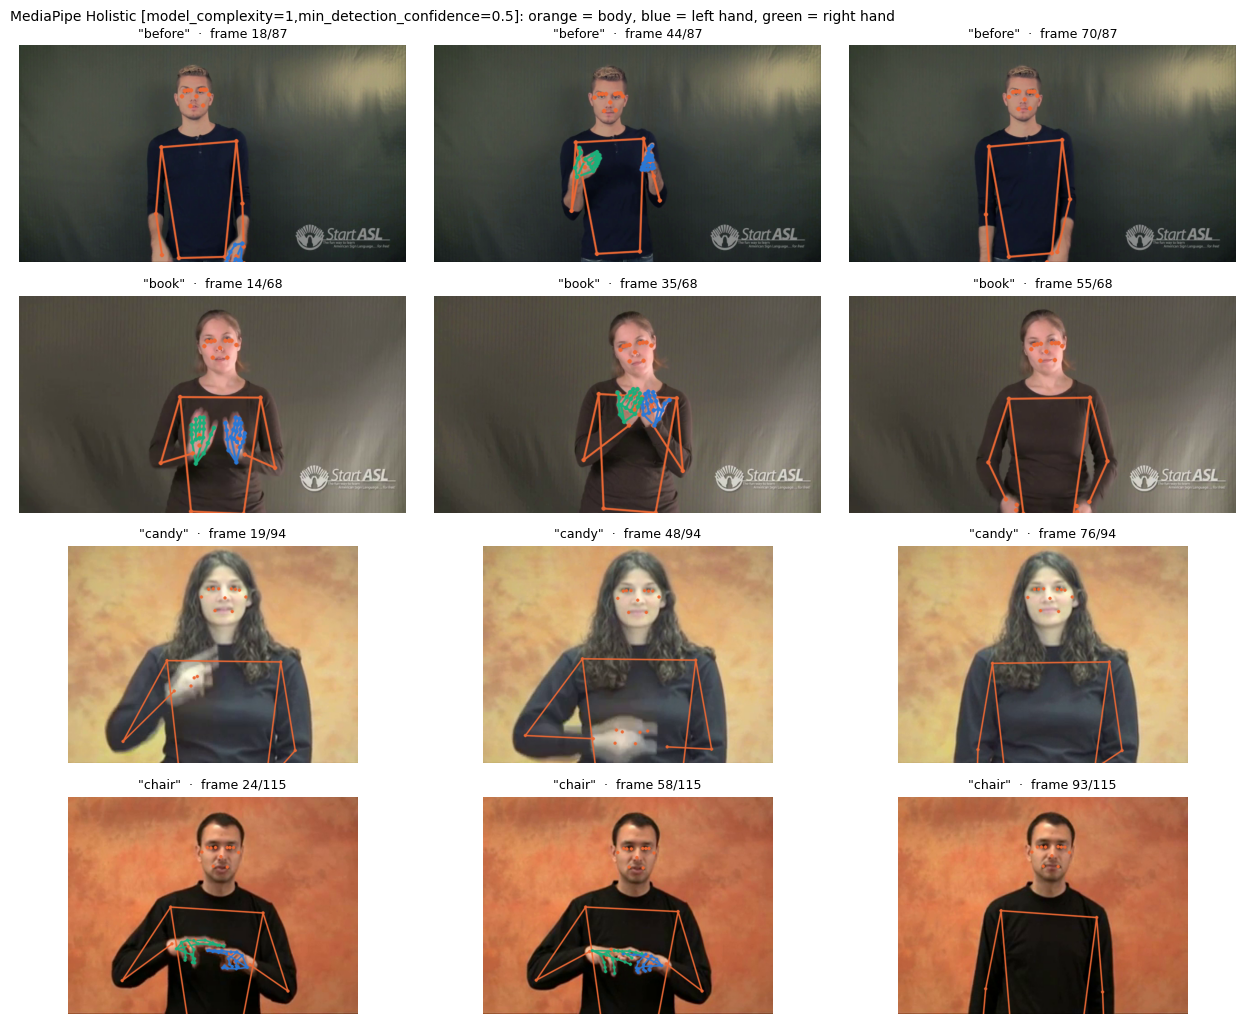

In [25]:
show_examples(videos, n_signs=4)

In [ ]:
scenarios = make_scenarios()
make_degraded_videos(videos, scenarios)

23 scenarios (list saved to results\asl_test\scenarios.csv)
degraded videos 1012/1012


In [ ]:
results = run_mediapipe(videos, scenarios)

[model_complexity=1,min_detection_confidence=0.5] 1058/1058 | codec_mjpeg rep 0 | ~0 min left          
1058 rows saved to results\asl_test\results.csv


In [28]:
summary, thresholds, confusion = analyze(results)

Saved summary.csv, thresholds.csv, confusion.csv in results\asl_test


In [29]:
thresholds

,setting,test,order,limit,original,last_ok_level,first_bad_level,value_there
0,"model_complexity=1,min_detection_confidence=0.5",codec,codec,confidence >= 0.75,0.888,mjpeg,none,NaN
1,"model_complexity=1,min_detection_confidence=0.5",compression,codec,confidence >= 0.75,0.888,51,none,NaN
2,"model_complexity=1,min_detection_confidence=0.5",fps,fps,confidence >= 0.75,0.888,5,none,NaN
3,"model_complexity=1,min_detection_confidence=0.5",resolution,resolution,confidence >= 0.75,0.888,96,none,NaN
4,"model_complexity=1,min_detection_confidence=0.5",codec,codec,pck >= 0.90,1.000,mjpeg,none,NaN
5,"model_complexity=1,min_detection_confidence=0.5",compression,codec,pck >= 0.90,1.000,38,43,0.870
6,"model_complexity=1,min_detection_confidence=0.5",fps,fps,pck >= 0.90,1.000,20,15,0.891
7,"model_complexity=1,min_detection_confidence=0.5",resolution,resolution,pck >= 0.90,1.000,96,none,NaN
8,"model_complexity=1,min_detection_confidence=0.5",codec,codec,detected_any_hand >= 0.75,0.582,none,libx264,0.579
9,"model_complexity=1,min_detection_confidence=0.5",compression,codec,detected_any_hand >= 0.75,0.582,none,23,0.583


### All metrics per scenario (mean, spread over repetitions, difference from the original)

In [30]:
show = ["confidence", "detected_any_hand", "pck", "error", "speed_fps"]
summary[["setting", "scenario"] + [c for m in show for c in (m, f"{m}_std", f"{m}_delta")]].round(3)

,setting,scenario,confidence,confidence_std,confidence_delta,detected_any_hand,detected_any_hand_std,detected_any_hand_delta,pck,pck_std,pck_delta,error,error_std,error_delta,speed_fps,speed_fps_std,speed_fps_delta
16,"model_complexity=1,min_detection_confidence=0.5",original,0.888,NaN,0.000,0.582,NaN,0.000,1.000,NaN,0.000,0.000,NaN,0.000,17.944,NaN,0.000
1,"model_complexity=1,min_detection_confidence=0.5",codec_libx264,0.882,NaN,-0.007,0.579,NaN,-0.003,0.925,NaN,-0.075,0.026,NaN,0.026,20.608,NaN,2.664
5,"model_complexity=1,min_detection_confidence=0.5",compression_23,0.887,NaN,-0.001,0.583,NaN,0.001,0.971,NaN,-0.029,0.015,NaN,0.015,22.392,NaN,4.448
14,"model_complexity=1,min_detection_confidence=0.5",fps_25,0.885,NaN,-0.003,0.574,NaN,-0.008,0.922,NaN,-0.078,0.024,NaN,0.024,21.764,NaN,3.821
21,"model_complexity=1,min_detection_confidence=0.5",resolution_540,0.888,NaN,-0.001,0.582,NaN,0.001,0.984,NaN,-0.016,0.010,NaN,0.010,19.406,NaN,1.463
2,"model_complexity=1,min_detection_confidence=0.5",codec_libx265,0.886,NaN,-0.002,0.571,NaN,-0.011,0.954,NaN,-0.046,0.019,NaN,0.019,22.692,NaN,4.748
6,"model_complexity=1,min_detection_confidence=0.5",compression_28,0.886,NaN,-0.002,0.582,NaN,0.000,0.966,NaN,-0.034,0.016,NaN,0.016,22.002,NaN,4.058
13,"model_complexity=1,min_detection_confidence=0.5",fps_20,0.881,NaN,-0.007,0.568,NaN,-0.013,0.925,NaN,-0.075,0.023,NaN,0.023,19.541,NaN,1.597
20,"model_complexity=1,min_detection_confidence=0.5",resolution_360,0.887,NaN,-0.001,0.585,NaN,0.004,0.977,NaN,-0.023,0.013,NaN,0.013,21.529,NaN,3.585
0,"model_complexity=1,min_detection_confidence=0.5",codec_libvpx-vp9,0.885,NaN,-0.003,0.579,NaN,-0.002,0.954,NaN,-0.046,0.020,NaN,0.020,23.017,NaN,5.073


### Metric vs. degradation level

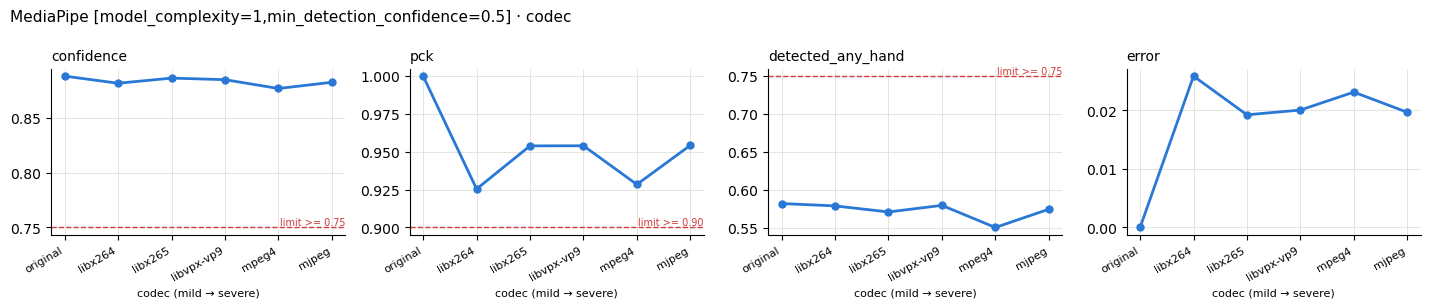

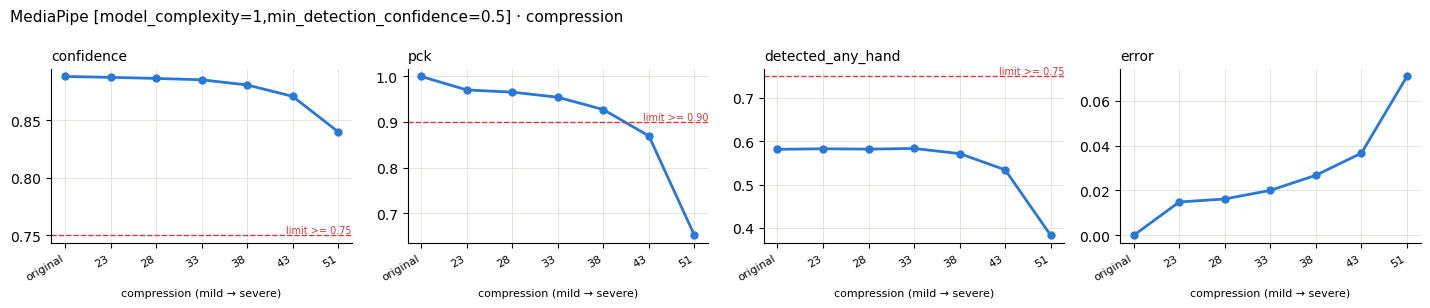

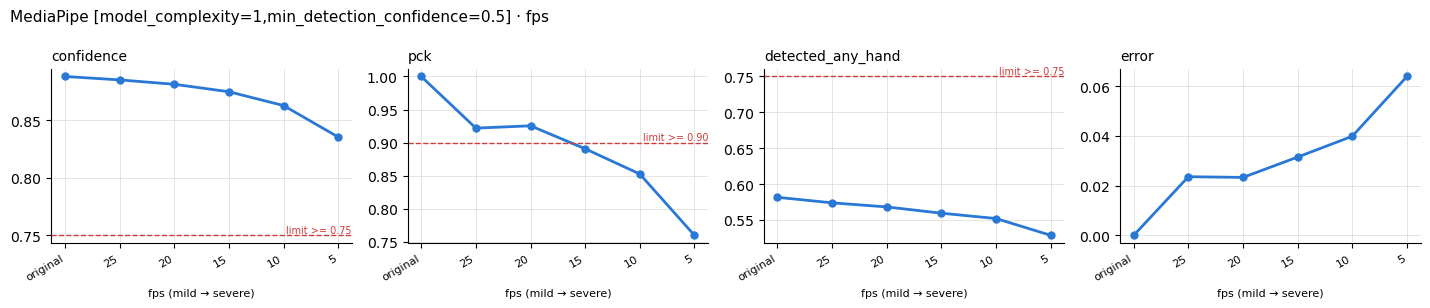

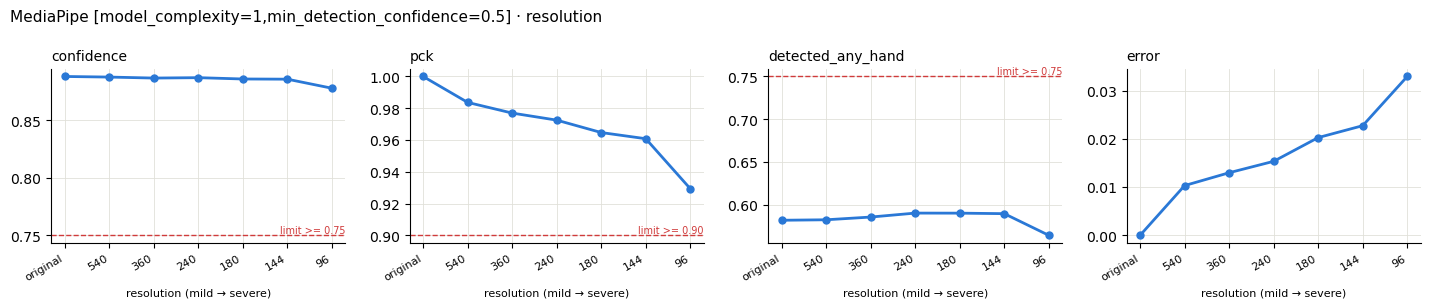

In [31]:
plot_curves(summary)

### Detection confusion matrices

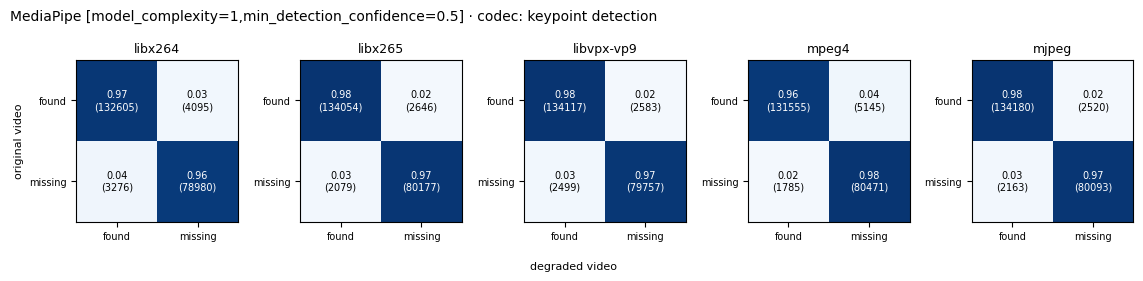

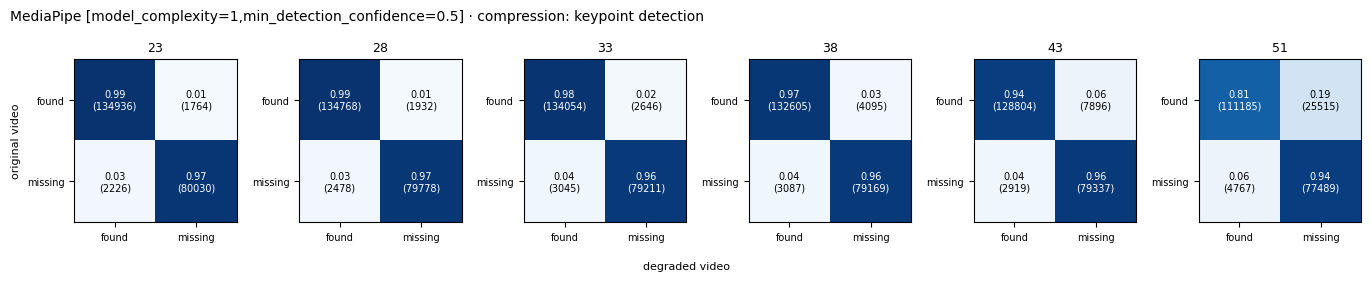

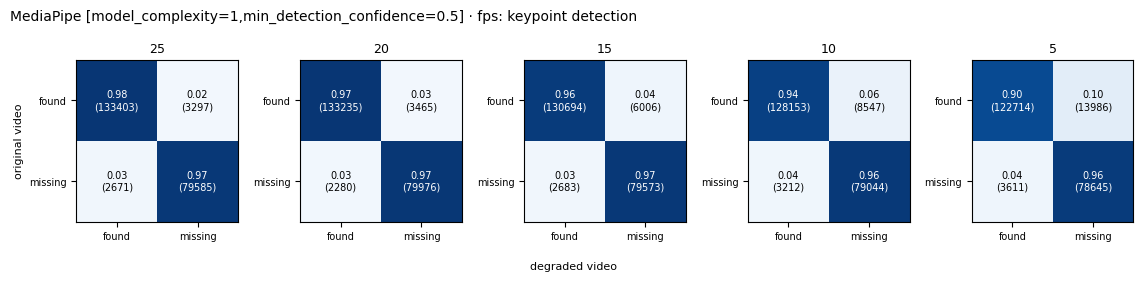

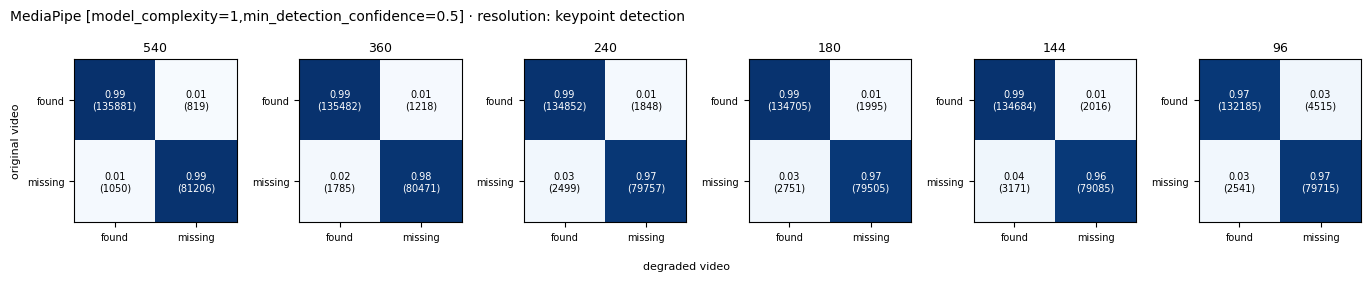

In [32]:
plot_confusion(confusion)

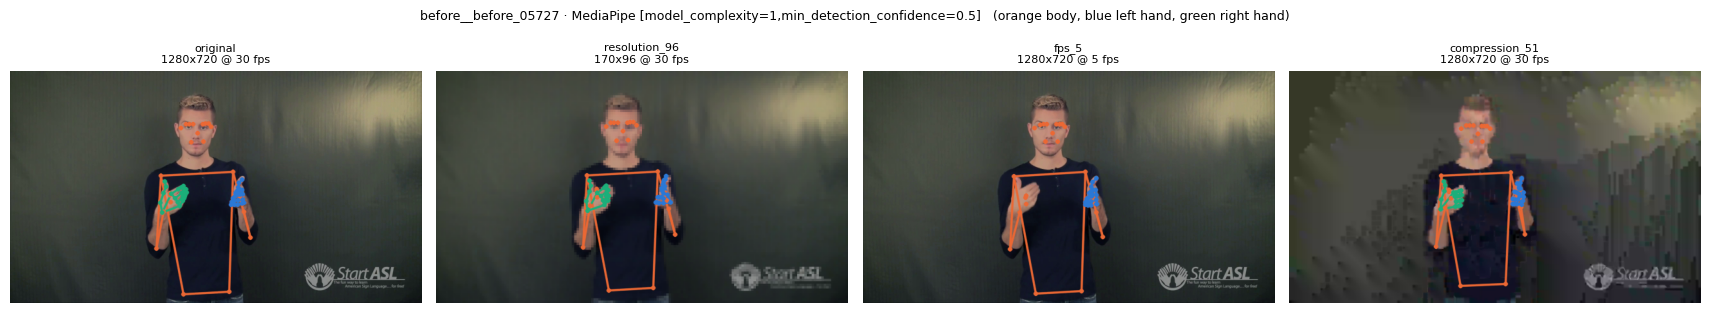

In [33]:
show_keypoints(videos, scenarios, video=0, scenario_names=["resolution_96", "fps_5", "compression_51"])

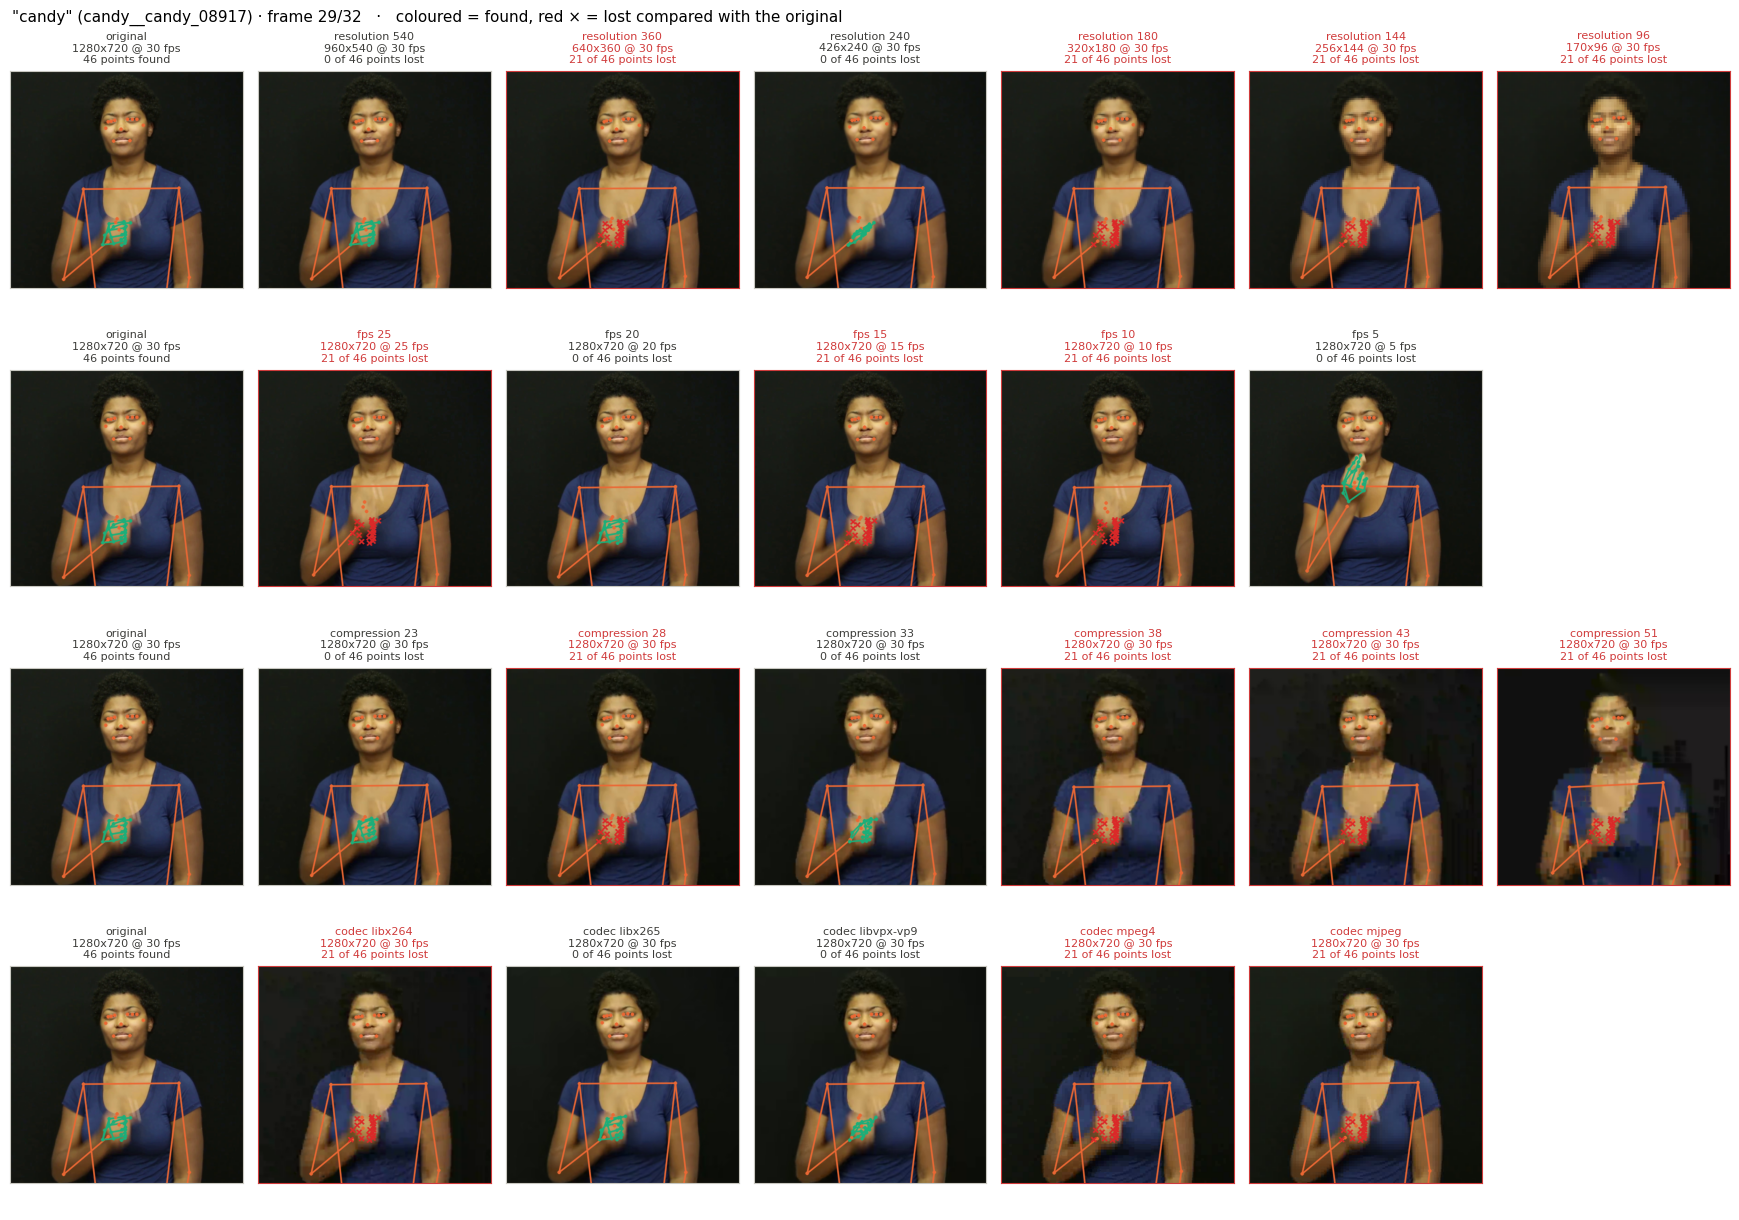

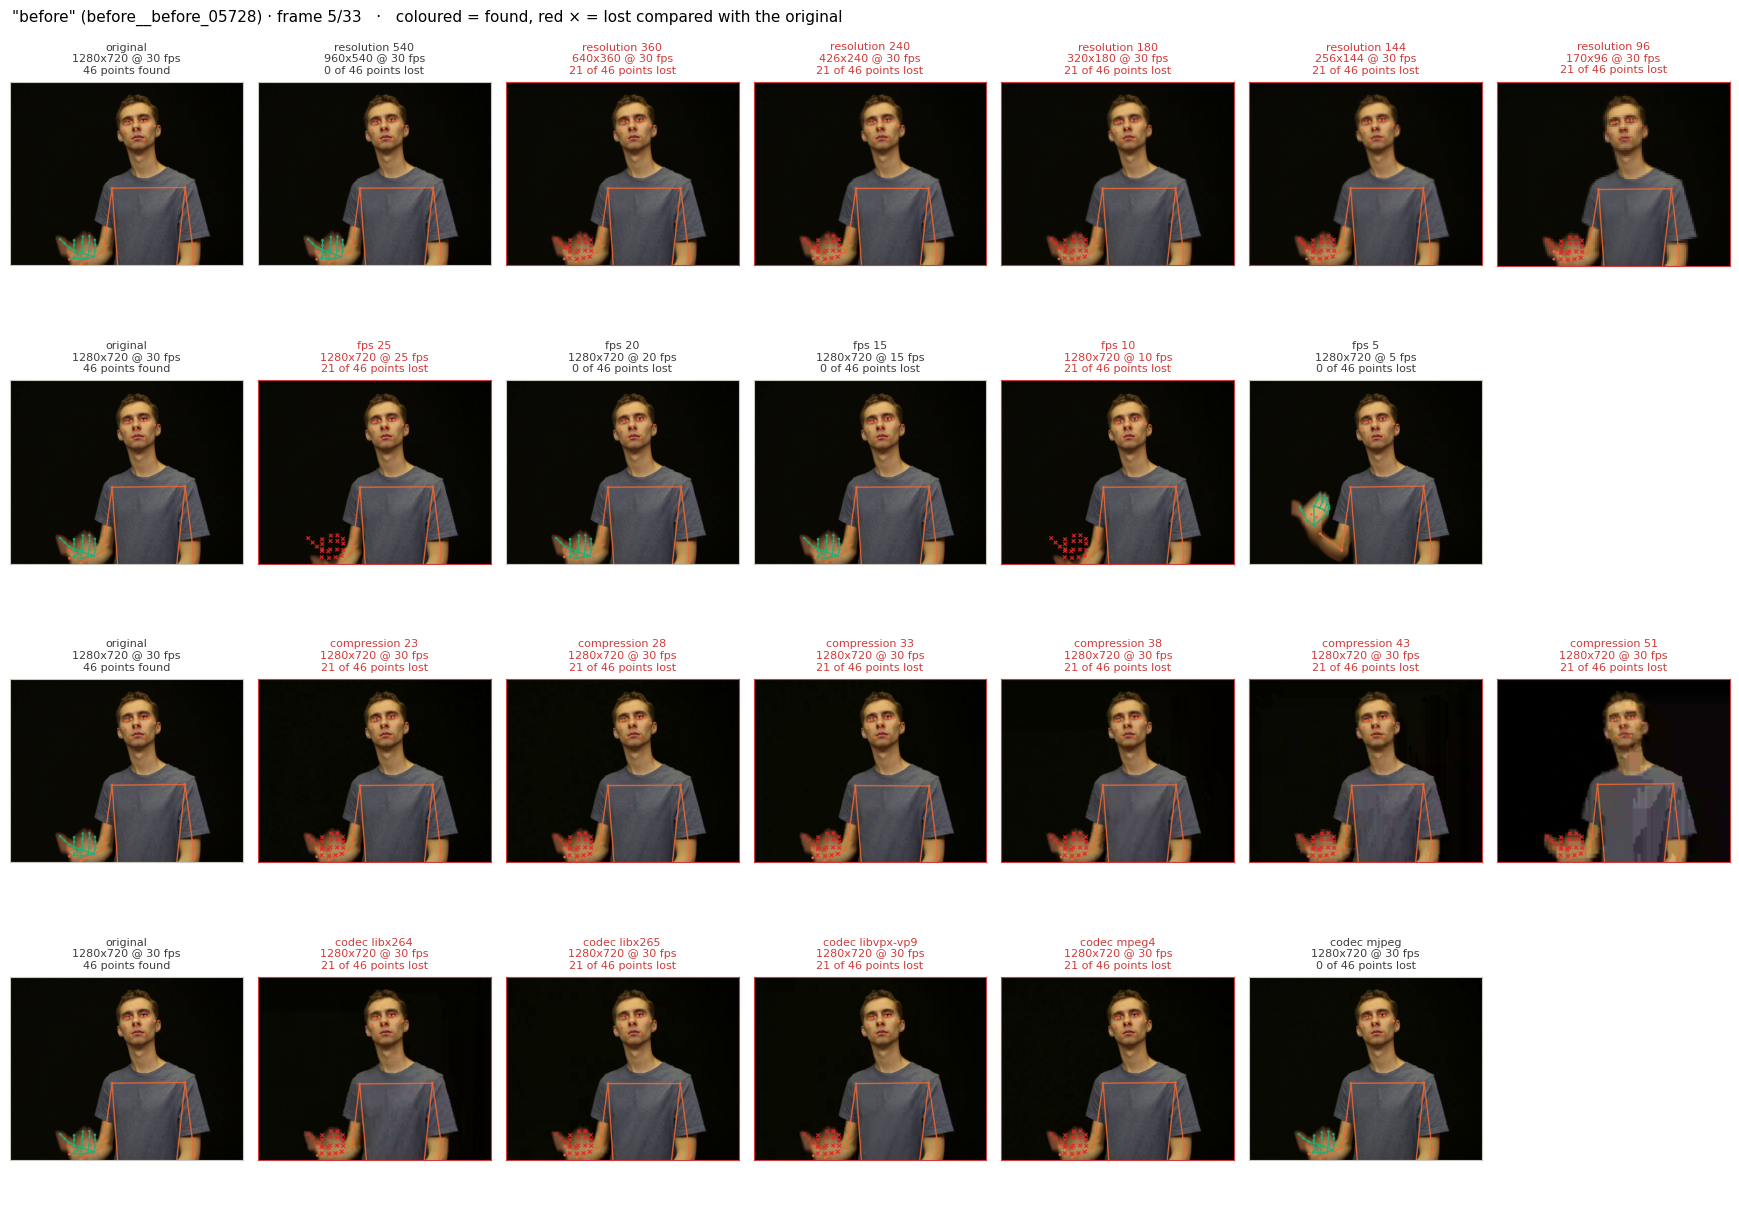

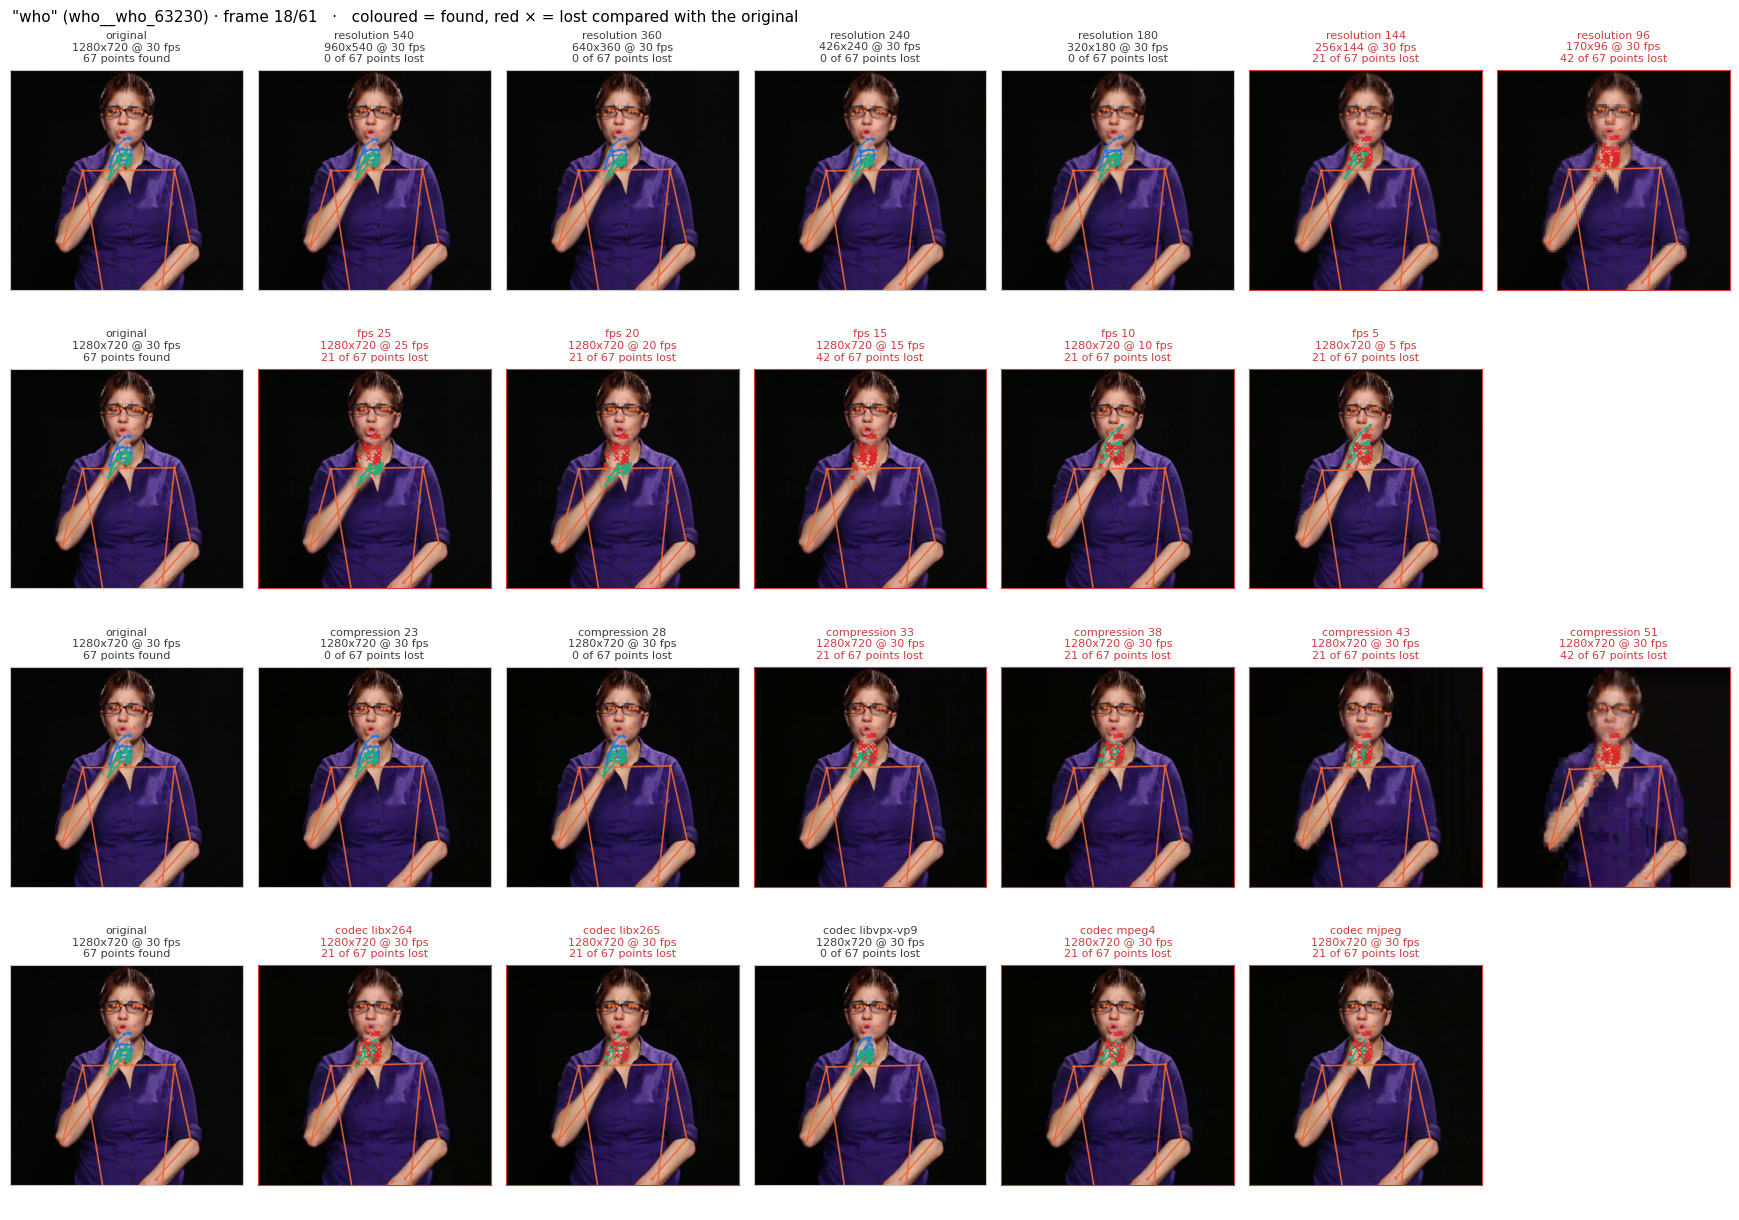

In [22]:
original = results[results.test == "original"].groupby("video").detected_any_hand.mean()
degraded = results[results.test != "original"].groupby("video").detected_any_hand.mean()
most_affected = (original - degraded).sort_values(ascending=False).index

for name in most_affected[:3]:
    show_degradation(videos, scenarios, name)

### A typical video, middle of the sign

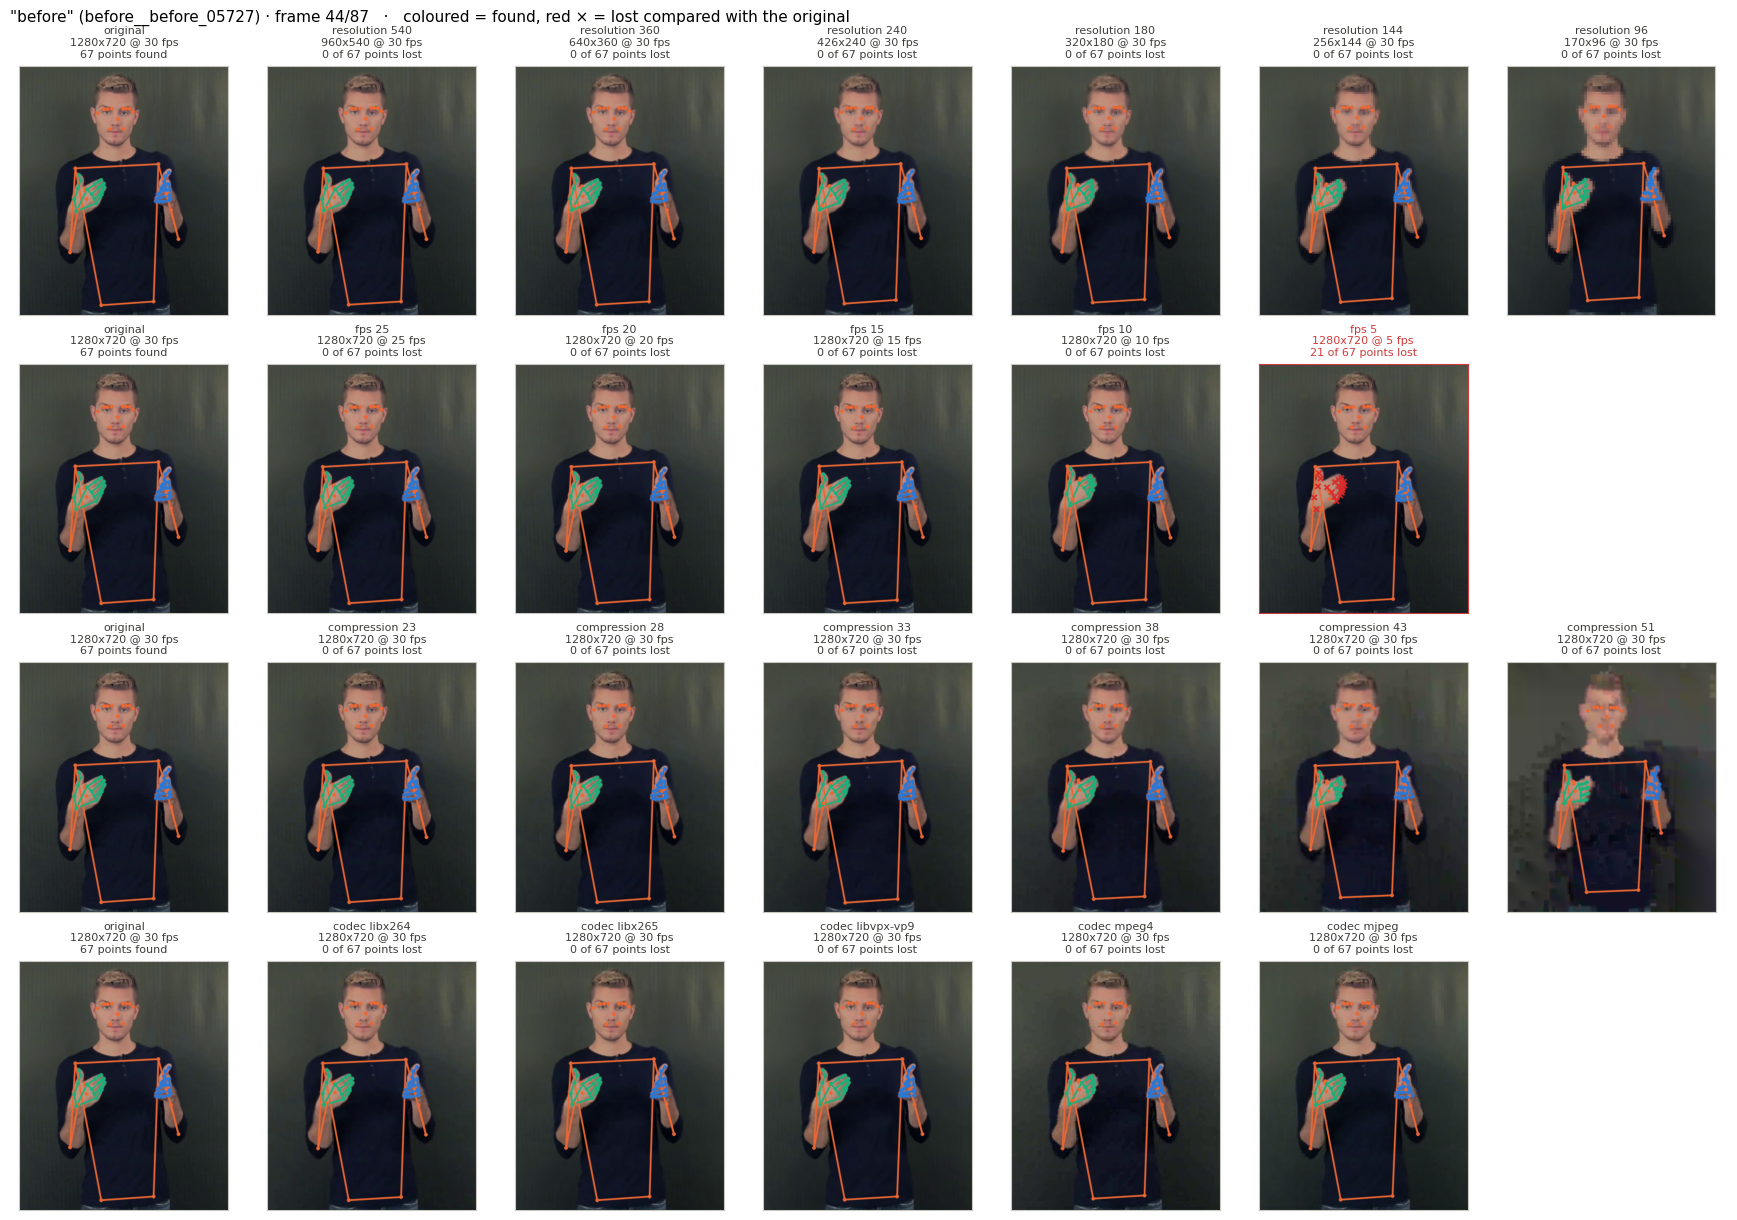

In [23]:
show_degradation(videos, scenarios, 0, frame=0.5)